# Zadanie 1

## 1.1

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

url = "https://drive.google.com/uc?id=1k-naWby25cTIlbwZ-71QdtfBVdkCMla6"

df = pd.read_csv(url)

df.head()
df.describe()

,x1,x2,y
count,100.000000,100.000000,100.000000
mean,-16.516452,194.787410,-187.672542
std,251.828994,114.163784,299.078952
min,-589.775534,6.635132,-916.994934
25%,-90.396867,90.159514,-325.494505
50%,-0.975545,199.571187,-158.721861
75%,89.149205,294.257264,-41.646005
max,558.750000,394.754775,805.000000


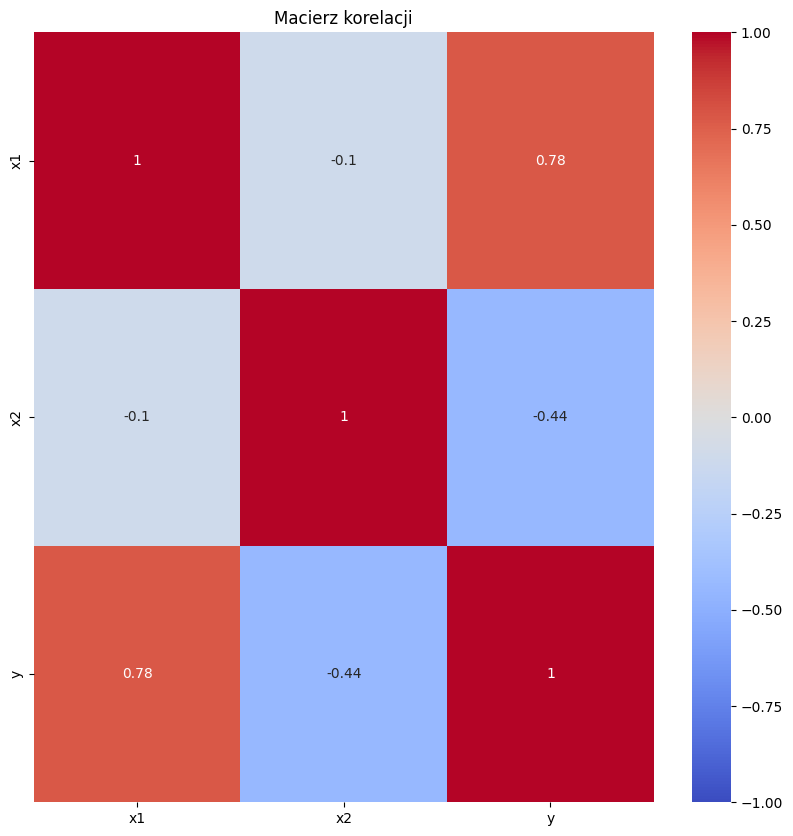

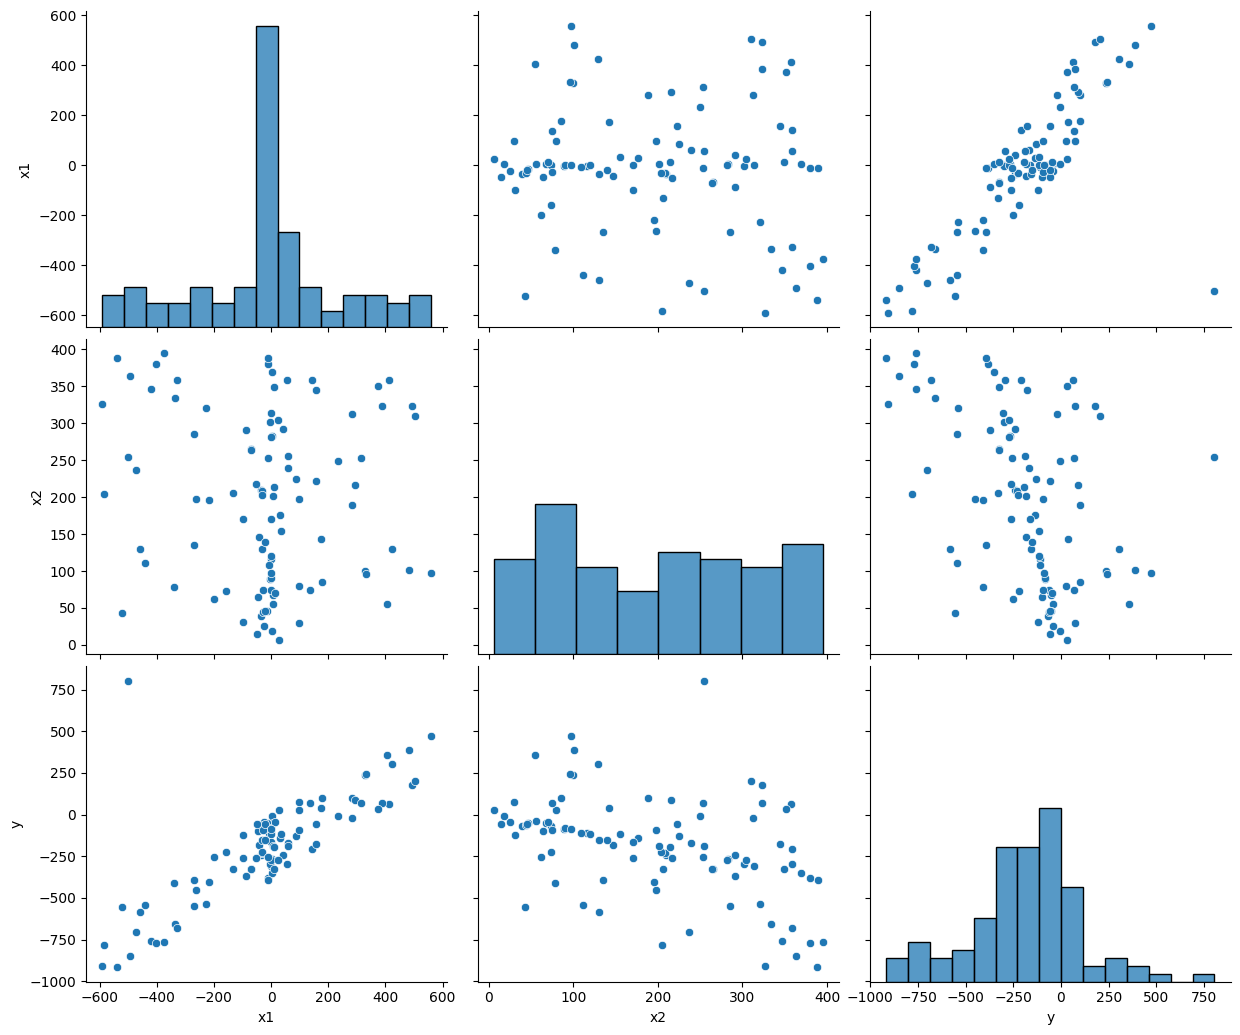

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Macierz korelacji")
plt.show()

sns.pairplot(df, height=3.5, aspect=1.2)
plt.show()

Można zaobserwować zależność liniową między x1 a y. Istnieje między nimi silna korelacja dodatnia. Widać też minimalnie zależność między x2 a y delikatna korelacja ujemna.

## 1.2

In [ ]:
def preprocess_data(X_train, y_train):
    p = 0.95

    mask = (
        (X_train['x1'] <= X_train['x1'].quantile(p)) &
        (X_train['x2'] <= X_train['x2'].quantile(p)) &
        (y_train <= y_train.quantile(p))
    )

    return X_train.loc[mask], y_train.loc[mask]


# Zadanie 2

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

X, y = df.drop('y', axis=1), df['y']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_p, y_p = preprocess_data(X_train, y_train)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_p, y_p, test_size=0.2, random_state=42
)


dummy_model = DummyRegressor(strategy='mean')
model = LinearRegression()

def eval_model(X_train, y_train, X_test, y_test, model, label):
    model.fit(X_train, y_train)

    if isinstance(model, LinearRegression):
        print(label)
        print(f"Współczynniki: {model.coef_}")
        print(f"Wyraz wolny: {model.intercept_}\n")
    elif isinstance(model, RidgeCV):
        print(label)
        print(f"Współczynniki: {model.coef_}")
        print(f"Wyraz wolny: {model.intercept_}\n")

    mse = mean_squared_error(y_test, model.predict(X_test))
    mae = mean_absolute_error(y_test, model.predict(X_test))
    rmse = np.sqrt(mse)
    score = model.score(X_test, y_test)

    return label, mse, mae, rmse, score


results = pd.DataFrame(
    columns=['Model', 'MSE', 'MAE', 'RMSE', 'Score']
)

results.loc[0] = [*eval_model(X_train, y_train, X_test, y_test, dummy_model, 'Dummy')]
results.loc[1] = [*eval_model(X_train, y_train, X_test, y_test, model, 'LinearRegression')]
results.loc[2] = [*eval_model(X_train_p, y_train_p, X_test_p, y_test_p, model, 'LinearRegression preprocessed')]
results.loc[3] = [*eval_model(X_train_p, y_train_p, X_test_p, y_test_p, dummy_model, 'Dummy preprocessed')]

display(results)


LinearRegression
Współczynniki: [ 0.86602687 -0.93133305]
Wyraz wolny: 10.154157940063044

LinearRegression preprocessed
Współczynniki: [ 1.00052938 -0.99742648]
Wyraz wolny: 7.716370022461405



,Model,MSE,MAE,RMSE,Score
0,Dummy,70092.425271,206.031212,264.749741,-0.039327
1,LinearRegression,1043.043946,26.221601,32.296191,0.984534
2,LinearRegression preprocessed,0.810085,0.724775,0.900047,0.999989
3,Dummy preprocessed,76713.655509,222.066520,276.972301,-0.028694


# Zadanie 3

In [ ]:
url = "https://drive.google.com/uc?id=1ArsNx-skt1m_Jy-1tZ5bKF6dqAbXAK0m"

df = pd.read_csv(url)

df.head()
# df.describe()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


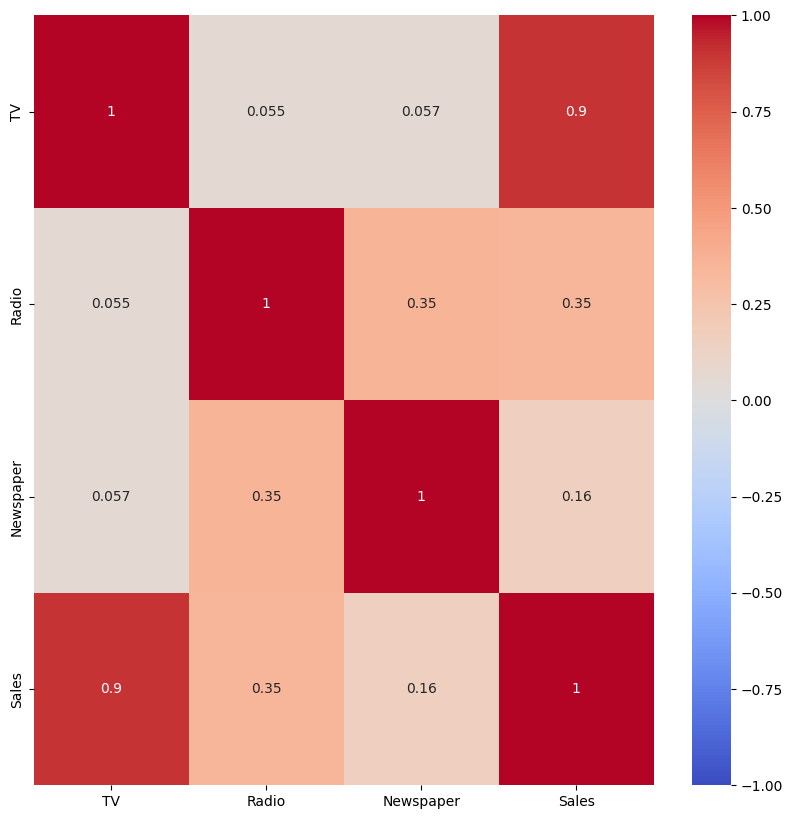

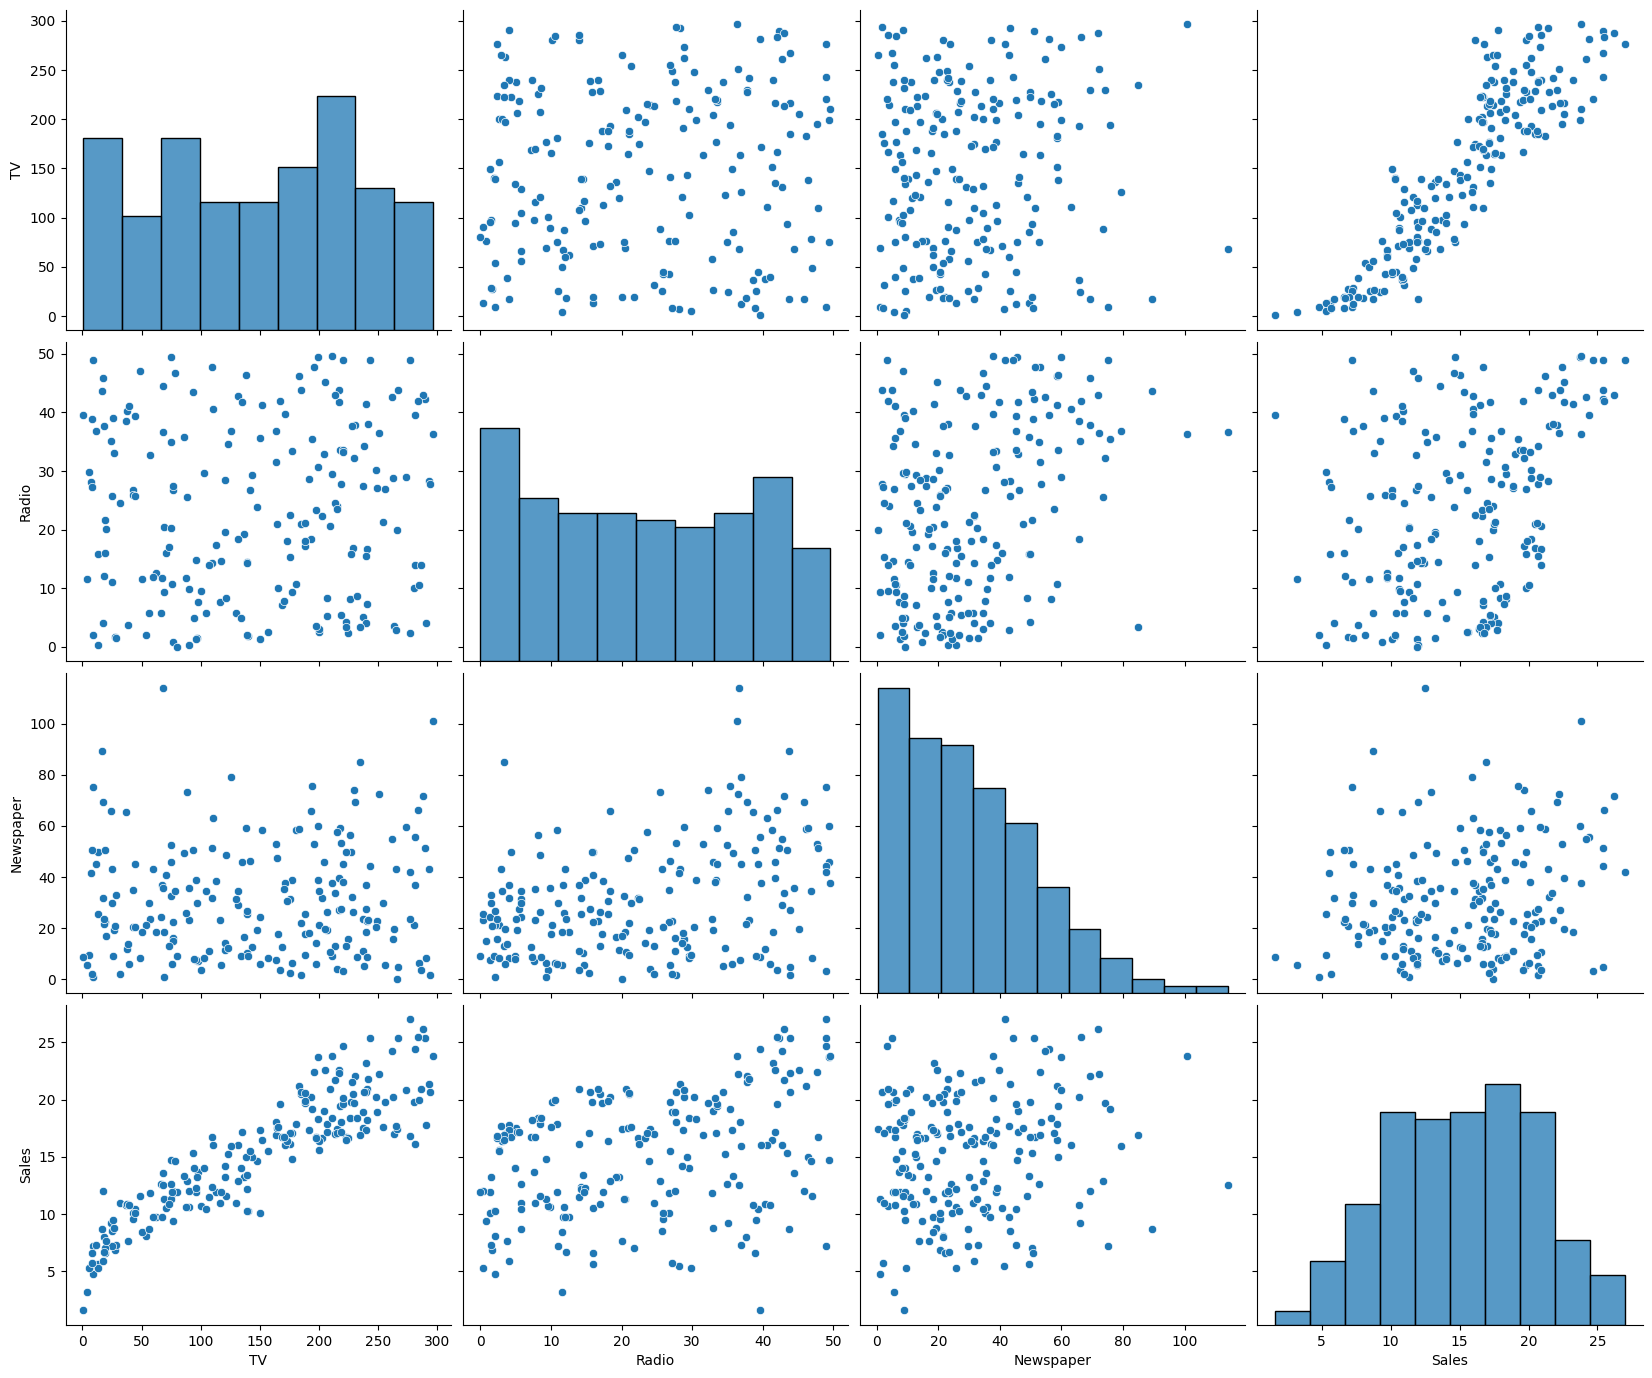

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

sns.pairplot(df, height=3.5, aspect=1.2)
plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Sales', axis=1), df['Sales'], test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

results = pd.DataFrame(
    columns=['Model', 'MSE', 'MAE', 'RMSE', 'Score']
)


results.loc[0] = [*eval_model(X_train, y_train, X_test, y_test, LinearRegression(), "LinearRegression")]
results.loc[1] = [*eval_model(X_train_norm, y_train, X_test_norm, y_test, LinearRegression(),"LinearRegression normalized")]

display(results)



LinearRegression
Współczynniki: [0.05450927 0.10094536 0.00433665]
Wyraz wolny: 4.714126402214127

LinearRegression normalized
Współczynniki: [4.58720774 1.48984025 0.08791597]
Wyraz wolny: 15.330625000000003



,Model,MSE,MAE,RMSE,Score
0,LinearRegression,2.907757,1.274826,1.705215,0.905901
1,LinearRegression normalized,2.907757,1.274826,1.705215,0.905901


# Zadanie 4

In [ ]:
url = "https://drive.google.com/uc?id=1juhOZq9O3br049irlV_Y4v6vxRDx6Btx"

df = pd.read_csv(url)

df.head()
df.describe()


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x11,x12,x13,x14,x15,x16,x17,x18,x19,y
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.066483,-0.090669,0.148793,-0.009252,0.066883,0.138678,-0.020263,0.135566,0.048246,0.021527,...,0.116212,0.181512,-0.021257,0.140830,0.164645,-0.083936,0.011392,-0.013781,-0.032560,10.844649
std,1.029991,0.977525,0.933608,0.895542,0.927696,0.923655,0.978568,0.946059,0.904497,1.078934,...,1.024664,1.045479,1.053048,0.921654,1.088579,1.063061,1.186164,1.007022,0.885011,93.584362
min,-2.896255,-1.975467,-2.499406,-2.172670,-2.423879,-1.703382,-1.748532,-1.760809,-2.471645,-3.241267,...,-2.198806,-2.619745,-2.591042,-2.872262,-2.152891,-2.696887,-2.940389,-2.151815,-2.650970,-189.273935
25%,-0.534866,-0.857052,-0.356271,-0.640109,-0.496090,-0.552580,-0.766607,-0.655722,-0.585946,-0.650129,...,-0.659615,-0.531525,-0.676945,-0.435979,-0.608664,-0.945732,-0.684015,-0.775432,-0.554979,-59.519171
50%,-0.028445,-0.076344,0.178798,-0.016458,0.131194,0.145691,-0.020941,0.147305,-0.012252,0.044188,...,0.214404,0.046091,-0.094711,0.174999,0.024079,-0.004435,0.091795,-0.022596,0.040263,1.554482
75%,0.757704,0.531959,0.721849,0.564199,0.493497,0.839220,0.622830,0.759989,0.654505,0.691722,...,0.819755,0.997346,0.648388,0.751524,0.860472,0.623706,0.821707,0.584392,0.591680,73.270708
max,2.290943,2.439752,2.526932,2.122156,3.137749,3.078881,2.270693,2.455300,2.133033,2.560085,...,2.601683,2.644343,3.193108,2.720169,3.852731,2.170943,2.558199,2.403416,1.765454,221.426107


Dane wyglądają na znormalizowane, średnia bliska 0, odchylenie standardowe bliskie 1.

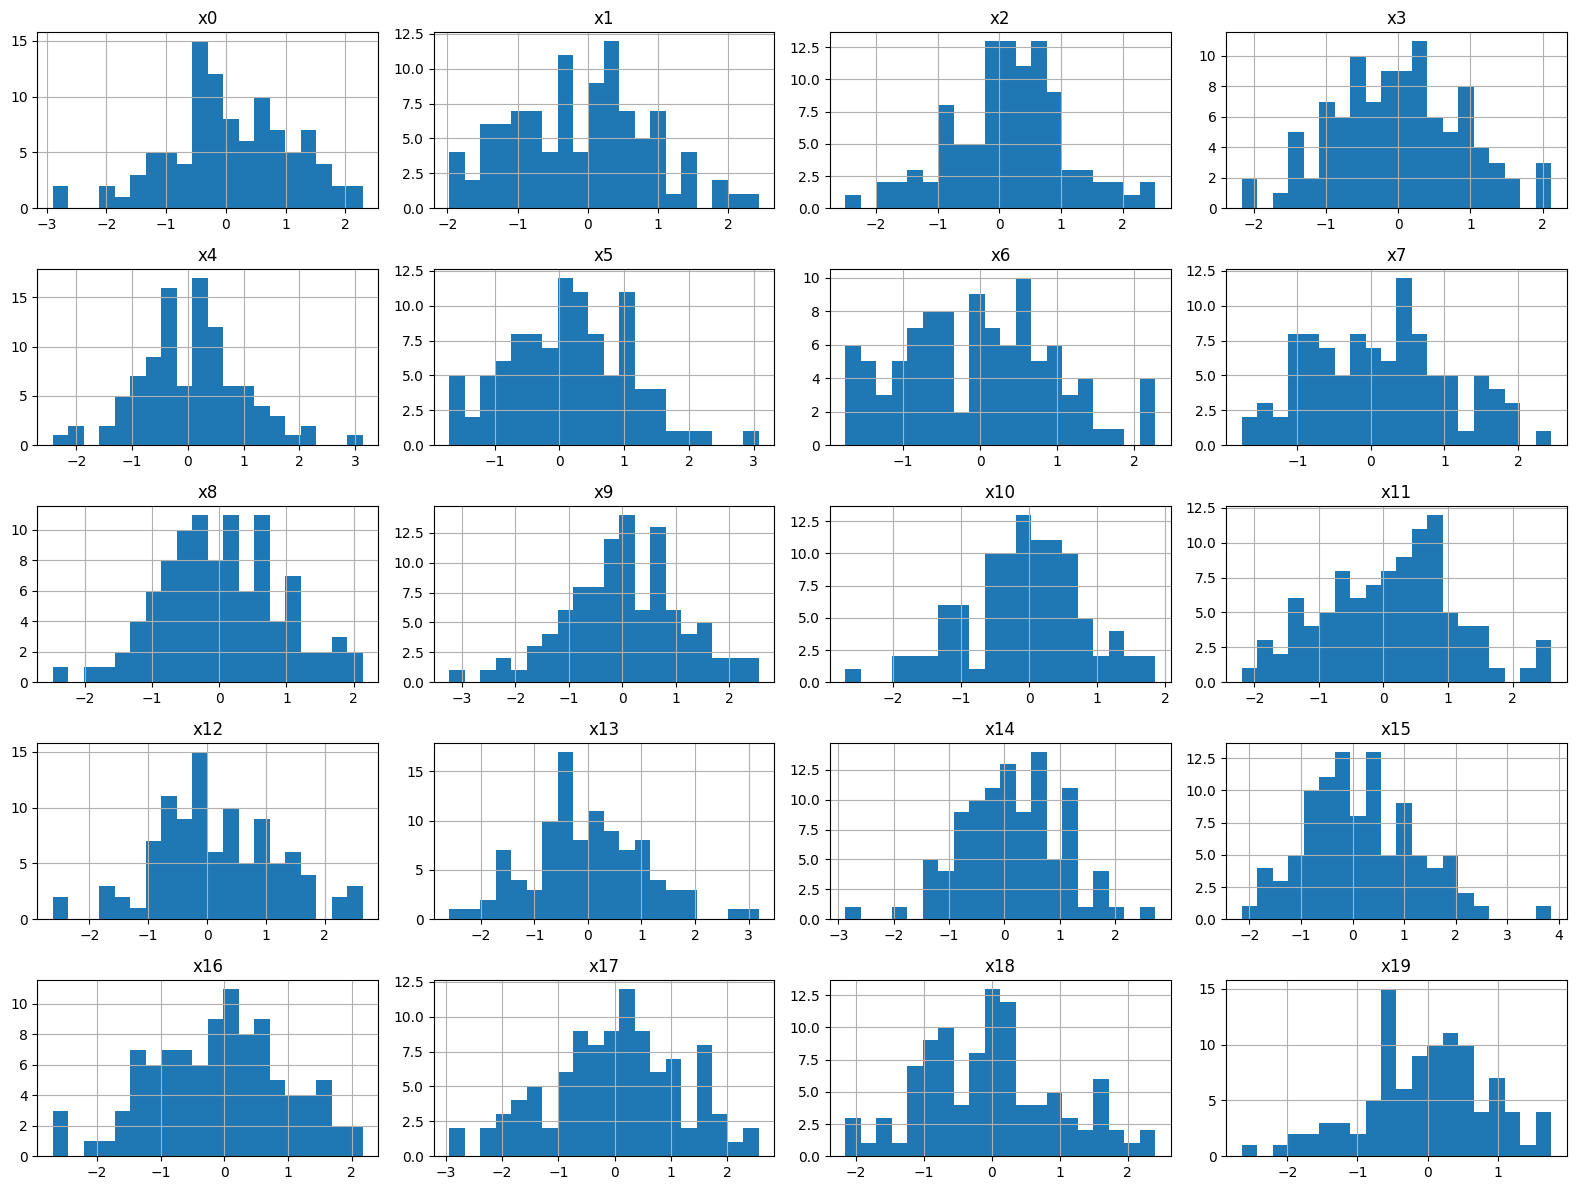

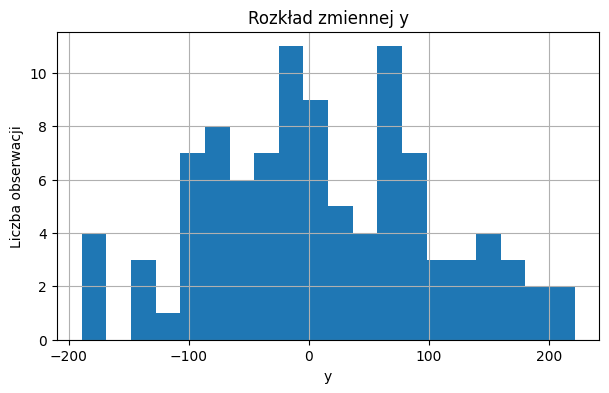

In [ ]:
X = df.drop(columns="y")

X.hist(figsize=(16, 12), bins=20)
plt.tight_layout()
plt.show()

df["y"].hist(bins=20, figsize=(7, 4))
plt.title("Rozkład zmiennej y")
plt.xlabel("y")
plt.ylabel("Liczba obserwacji")
plt.show()

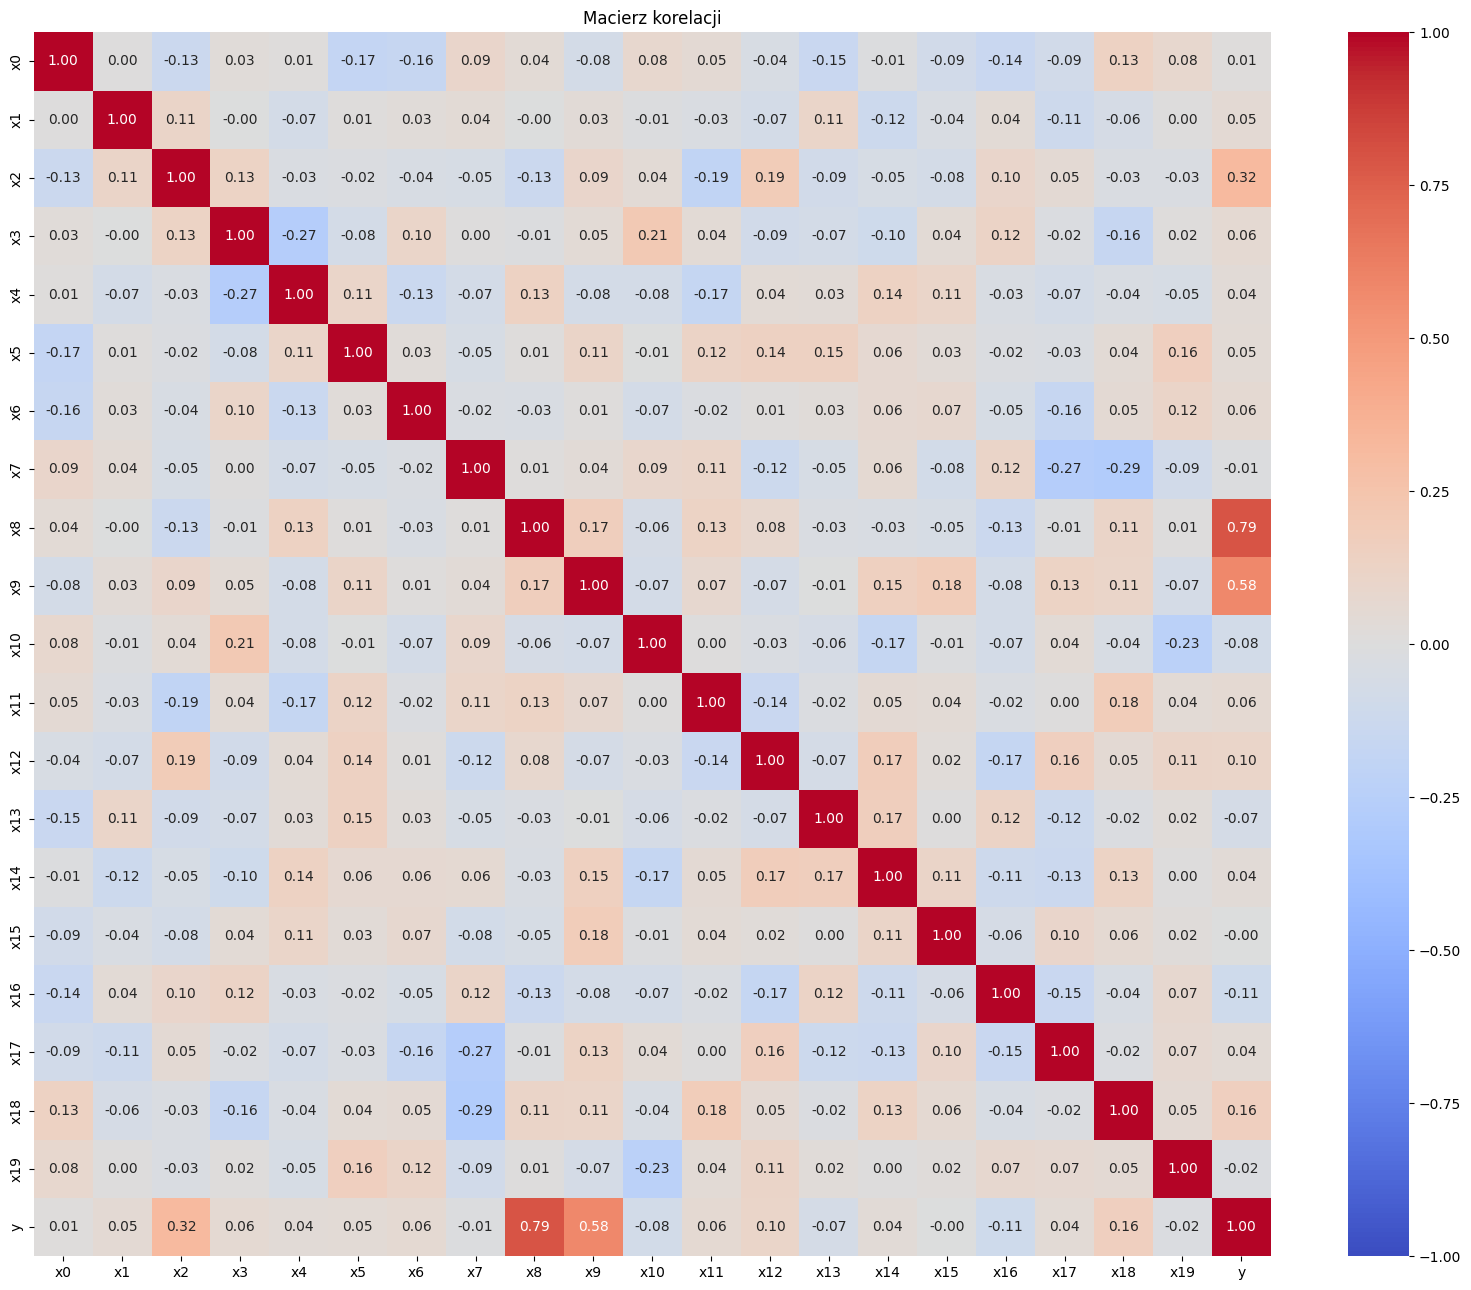

In [ ]:
plt.figure(figsize=(16, 13))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Macierz korelacji")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import RidgeCV

X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"), df["y"], test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

model = LinearRegression()
model_ridge = RidgeCV(
        alphas=np.logspace(-4, 4, 100),
        scoring="neg_mean_squared_error",
        cv=5
    )
results = pd.DataFrame(
    columns=['Model', 'MSE', 'MAE', 'RMSE', 'Score']
)

results.loc[0] = [*eval_model(X_train_norm, y_train, X_test_norm, y_test, model, "LinearRegression")]
results.loc[1] = [*eval_model(X_train_norm, y_train, X_test_norm, y_test, model_ridge, "Ridge")]
results.loc[2] = [*eval_model(X_train, y_train, X_test, y_test, model, "LinearRegression without normalization")]
results.loc[3] = [*eval_model(X_train, y_train, X_test, y_test, model_ridge, "Ridge without normalization")]

display(results)

LinearRegression
Współczynniki: [ 9.25536018e+00 -6.70518471e-01  3.51591782e+01  4.40961428e-01
 -1.70666145e+00  4.18541817e-01  1.01846569e+01 -1.04308722e+00
  7.25217609e+01  3.94028345e+01 -1.81878362e+00 -1.77822577e+00
 -2.34449307e+00  1.16270959e+00  9.68862225e-01 -2.45354455e+00
  6.08592373e-01  6.52442141e-02  1.28540313e+00 -1.77904009e+00]
Wyraz wolny: 9.823623774124998

Ridge
Współczynniki: [ 9.08561003 -0.63184874 34.8896313   0.51300697 -1.62724982  0.35683981
 10.03954155 -0.97270734 72.08637948 39.26497903 -1.84801425 -1.68919117
 -2.26635422  1.12726501  1.0084068  -2.52022007  0.53504399  0.07919684
  1.32465619 -1.71688967]
Wyraz wolny: 9.823623774124998

LinearRegression without normalization
Współczynniki: [ 8.89641770e+00 -6.91714923e-01  3.91929611e+01  4.93922866e-01
 -1.76285533e+00  4.90761771e-01  1.03854911e+01 -1.11034244e+00
  7.91395414e+01  3.83905113e+01 -2.13883213e+00 -1.72940888e+00
 -2.38869110e+00  1.09670471e+00  1.02380887e+00 -2.20733230e+0

,Model,MSE,MAE,RMSE,Score
0,LinearRegression,232.826824,12.657664,15.258664,0.968985
1,Ridge,230.978910,12.501484,15.197990,0.969232
2,LinearRegression without normalization,232.826824,12.657664,15.258664,0.968985
3,Ridge without normalization,233.612069,12.615157,15.284373,0.968881
